# Passau MedCo · Task 2: Training and Evaluating an Attrition Classifier

**Micro-level goal 1.2:** choose a classification algorithm, set its hyperparameters, train it and evaluate it.

This notebook compares two gradient-boosting libraries, **LightGBM** and **XGBoost**, against two simple reference models. The better of the two boosting models becomes the final model. Its fitted pipeline and the data splits are exported for the separate LIME notebook.

**Why not logistic regression?** The earlier notebooks ([model_comparison.ipynb](model_comparison.ipynb), [logistic_regression.ipynb](logistic_regression.ipynb)) showed that a logistic regression ranks employees well on this data. However, its coefficients already explain how it works. Our task is to make a model explainable with LIME, which fits a simple *linear* model around a single prediction. Applied to a logistic regression, LIME would mostly repeat what the coefficients already show. We therefore use a tree ensemble that cannot be read directly. Logistic regression remains in this notebook as a reference.

Not part of this notebook: the exploratory analysis (see [01_eda.ipynb](01_eda.ipynb)) and any explanation method (LIME, SHAP, feature importances). Those live in their own notebooks.

**Workflow**

1. Load and clean the data exactly as in the EDA.
2. Hold out a stratified 20% test set and leave it untouched until the final evaluation.
3. Compare the reference models, LightGBM and XGBoost on the same five cross-validation folds of the training set, and tune both boosting models there.
4. Choose the decision threshold on out-of-fold predictions from the training set.
5. Evaluate the final model once on the test set, export it and answer the guiding questions.

In [1]:
import time
from pathlib import Path

import joblib
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from IPython.display import display
from lightgbm import LGBMClassifier
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from xgboost import XGBClassifier

%matplotlib inline

RANDOM_STATE = 42  # used for the split, the CV folds, the searches and the models
ARTIFACT_DIR = Path("artifacts")
CLASS_LABELS = ["Stays", "Leaves"]  # index 0 = stays, 1 = leaves (Attrition = "Yes")

# Project colours from the EDA: teal for the final model, orange for the reference model.
FINAL_COLOR, REFERENCE_COLOR, INK, MUTED = "#28788a", "#e8702a", "#334155", "#94a3b8"

print(f"scikit-learn {sklearn.__version__} · LightGBM {lightgbm.__version__} · XGBoost {xgboost.__version__}")

scikit-learn 1.9.1 · LightGBM 4.7.0 · XGBoost 3.4.1


## 1. Load and clean the data

Same steps as in the EDA: strip padded headers and text values, turn empty strings into missing values and repeat the quality checks. The target is coded as **1 = leaves** (`Attrition = "Yes"`) and **0 = stays**.

In [2]:
csv_path = Path("data") / "employee-attrition.csv"
employees = pd.read_csv(csv_path)
employees.columns = employees.columns.str.strip()
for column in employees.select_dtypes(include="str"):
    employees[column] = employees[column].str.strip().replace("", pd.NA)

assert not employees.isna().any().any(), "Review missing values."
assert not employees.duplicated().any(), "Review duplicate employee rows."
assert employees["EmployeeNumber"].is_unique, "Review duplicate employee IDs."
assert set(employees["Attrition"]) == {"Yes", "No"}, "Review the Attrition labels."

target = employees["Attrition"].eq("Yes").astype(int)  # 1 = leaves, 0 = stays
print(f"{len(employees):,} employees · {employees.shape[1]} columns · {target.sum()} leavers ({target.mean():.1%})")

1,470 employees · 35 columns · 237 leavers (16.1%)


### Which columns go into the model?

Four columns carry no usable information and are dropped, as in the EDA:

- `EmployeeCount` (always 1), `StandardHours` (always 80) and `Over18` (always "Y") are constant.
- `EmployeeNumber` is an ID. A model could at best memorise it, which does not generalise to new employees.

The remaining 30 columns are kept. Seven are text categories. The other 23 are numbers, including ordered codes such as `JobLevel` or `WorkLifeBalance`, which tree models can split on directly.

`PerformanceRating` is fully determined by `PercentSalaryHike` in this dataset (rating 4 exactly when the raise is at least 20%, see EDA). This is redundancy, not leakage, and trees cope with it. It matters for LIME later, because perturbing one of the two columns independently creates combinations that never occur in the data.

In [3]:
constant_columns = ["EmployeeCount", "StandardHours", "Over18"]
id_columns = ["EmployeeNumber"]
assert employees[constant_columns].nunique().eq(1).all(), "These columns are expected to be constant."

categorical_columns = [
    "BusinessTravel", "Department", "EducationField", "Gender", "JobRole", "MaritalStatus", "OverTime",
]
numeric_columns = [
    column for column in employees.columns
    if column not in {"Attrition", *constant_columns, *id_columns, *categorical_columns}
]
# One fixed column order shared by the raw frame, the encoded matrix and the exported feature names:
# the seven categorical columns first, then the numeric columns in CSV order.
feature_names = [*categorical_columns, *numeric_columns]
features = employees[feature_names]

assert set(features.select_dtypes(include="str").columns) == set(categorical_columns)
print(f"{len(feature_names)} features: {len(categorical_columns)} categorical, {len(numeric_columns)} numeric")
print("Dropped:", ", ".join([*constant_columns, *id_columns]))

30 features: 7 categorical, 23 numeric
Dropped: EmployeeCount, StandardHours, Over18, EmployeeNumber


## 2. Hold out a test set

**Split:** stratified 80/20 with `random_state=42`. This is the same partition as the training table in the EDA and the earlier model notebooks. Stratification keeps the attrition share at about 16% in both parts, and 20% still leaves 47 leavers for the final check. After this cell the test set is not used again until Section 8.

**Known limitation:** the same 294 test employees were already reported in the earlier notebooks ([model_comparison.ipynb](model_comparison.ipynb), [logistic_regression.ipynb](logistic_regression.ipynb)), and the EDA describes the full CSV. Nothing in this notebook is tuned on the test set, but across the project it is no longer completely fresh. The cross-validation results on the training set are therefore the main basis for model selection, and the test result serves as a confirmation.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    features, target, test_size=0.20, stratify=target, random_state=RANDOM_STATE
)
assert (len(y_train), y_train.sum(), len(y_test), y_test.sum()) == (1176, 190, 294, 47), "Split differs from the EDA."

display(pd.DataFrame({
    "Employees": [len(y_train), len(y_test)],
    "Leavers": [y_train.sum(), y_test.sum()],
    "Attrition (%)": [100 * y_train.mean(), 100 * y_test.mean()],
}, index=["Train", "Test"]).round(1))

,Employees,Leavers,Attrition (%)
Train,1176,190,16.2
Test,294,47,16.0


## 3. Encode the categories inside a pipeline

Tree models split on thresholds, so numeric columns need no scaling and pass through unchanged. The seven text columns become integer codes via an `OrdinalEncoder`:

- **Why integer codes instead of one-hot indicators?** The LIME notebook needs each categorical variable as *one* column with a known code-to-label mapping (`categorical_features`, `categorical_names`). Trees can still isolate any single category with one or two splits.
- **Order of the codes.** Codes follow alphabetical order, except for `BusinessTravel`. It keeps its natural order *Non-Travel < Travel_Rarely < Travel_Frequently*, so that a higher code means more travel.
- **No leakage.** The category lists are taken from the training rows, and the encoder sits inside the pipeline. Unknown categories in new data would get the code −1 instead of raising an error.

The complete pipeline (encoder + model) accepts the cleaned raw DataFrame, so `pipeline.predict_proba(X)` works on rows straight from the CSV.

In [5]:
travel_order = ["Non-Travel", "Travel_Rarely", "Travel_Frequently"]
assert set(X_train["BusinessTravel"]) == set(travel_order)
category_order = [
    travel_order if column == "BusinessTravel" else sorted(X_train[column].unique())
    for column in categorical_columns
]


def make_tree_preprocessor():
    # Integer-code the categorical columns, pass numeric columns through, keep the `feature_names` order.
    encoder = OrdinalEncoder(categories=category_order, handle_unknown="use_encoded_value", unknown_value=-1)
    return ColumnTransformer(
        [("categorical", encoder, categorical_columns), ("numeric", "passthrough", numeric_columns)],
        verbose_feature_names_out=False,
    )


preview = make_tree_preprocessor().fit(X_train)
assert list(preview.get_feature_names_out()) == feature_names
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(
        {"Integer codes": {
            column: " · ".join(f"{code} = {label}" for code, label in enumerate(categories))
            for column, categories in zip(categorical_columns, preview.named_transformers_["categorical"].categories_)
        }}
    ))

,Integer codes
BusinessTravel,0 = Non-Travel · 1 = Travel_Rarely · 2 = Travel_Frequently
Department,0 = Human Resources · 1 = Research & Development · 2 = Sales
EducationField,0 = Human Resources · 1 = Life Sciences · 2 = Marketing · 3 = Medical · 4 = Other · 5 = Technical Degree
Gender,0 = Female · 1 = Male
JobRole,0 = Healthcare Representative · 1 = Human Resources · 2 = Laboratory Technician · 3 = Manager · 4 = Manufacturing Director · 5 = Research Director · 6 = Research Scientist · 7 = Sales Executive · 8 = Sales Representative
MaritalStatus,0 = Divorced · 1 = Married · 2 = Single
OverTime,0 = No · 1 = Yes


## 4. How are the models compared?

**Same folds for every model.** All comparisons and all tuning use one fixed stratified 5-fold split of the 1,176 training employees (`shuffle=True`, `random_state=42`). Each validation fold holds about 235 employees, 38 of them leavers.

**Metrics.** With 16% leavers, a model that always predicts "stays" is right 84% of the time while finding no leaver at all. Accuracy is therefore reported only on the side.

| Metric | What it answers | Role |
|---|---|---|
| **PR-AUC** (average precision) | How precise are the alerts, averaged over all recall levels? A random ranking scores about 0.16 (the share of leavers). | **Selection criterion** |
| ROC-AUC | How likely is a random leaver to get a higher score than a random stayer? 0.5 = chance. | Supporting |
| F1 (class "Leaves") | Balance of precision and recall for leavers at the default threshold of 0.5. | Supporting |
| Accuracy | Share of all employees classified correctly. | Side note only |

PR-AUC is the main criterion because it focuses on the rare class HR cares about. ROC-AUC can look good even when most alerts are false alarms.

**Class imbalance: class weights instead of SMOTE.** In both boosting models, errors on leavers count about 5.2 times as much as errors on stayers (`scale_pos_weight` = stayers / leavers in the training set). The same value is used for LightGBM and XGBoost.

- Weights use only real employees. SMOTE would interpolate synthetic employees and produce impossible values for integer-coded categories (e.g. a job role "3.4") and for discrete scales.
- No resampling step has to be confined to each CV fold to avoid leakage, and the pipeline stays a plain scikit-learn pipeline for LIME.
- Both libraries support the weights natively.

Side effect: weighted models produce scores that overstate the actual probability of leaving. Their scores should be read as a risk *ranking*, not as calibrated percentages, and the decision threshold is chosen separately (Section 7).

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_folds = list(cv.split(X_train, y_train))  # materialised once, so every model sees identical folds

scoring = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "f1": make_scorer(f1_score, zero_division=0),  # F1 of class 1 ("Leaves") at threshold 0.5
    "accuracy": "accuracy",
}
metric_names = {"pr_auc": "PR-AUC", "roc_auc": "ROC-AUC", "f1": "F1 (Leaves)", "accuracy": "Accuracy"}

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("Leavers per validation fold:", [int(y_train.iloc[valid].sum()) for _, valid in cv_folds])
print(f"scale_pos_weight = {(y_train == 0).sum()} / {(y_train == 1).sum()} = {scale_pos_weight:.2f}")


def summarize_folds(fold_scores, models):
    # Mean ± standard deviation across the five folds, one row per model.
    grouped = fold_scores.groupby("Model")[list(scoring)]
    means, sds = grouped.mean().reindex(models), grouped.std().reindex(models)
    table = pd.DataFrame(index=models)
    for metric, label in metric_names.items():
        table[label] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(means[metric], sds[metric])]
    return table

Leavers per validation fold: [38, 38, 38, 38, 38]
scale_pos_weight = 986 / 190 = 5.19


## 5. Reference models

- **Dummy classifier:** always predicts the majority class "stays". It shows what 84% accuracy is worth here: nothing.
- **Logistic regression:** a simple linear model with standardised numeric inputs, `class_weight="balanced"` and default regularisation (`C=1`), without tuning. A linear model cannot use arbitrary integer codes such as "JobRole = 5", so this reference gets one-hot indicators for the seven text columns. With integer codes, it would be an artificially weak reference. The one-hot encoding is used only here. The final model keeps the integer codes needed for LIME.

In [7]:
baselines = {
    "Dummy (always 'stays')": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": Pipeline([
        ("preprocess", ColumnTransformer([
            ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
            ("numeric", StandardScaler(), numeric_columns),
        ])),
        ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)),
    ]),
}

fold_rows = []
for name, model in baselines.items():
    result = cross_validate(model, X_train, y_train, cv=cv_folds, scoring=scoring)
    for fold in range(len(cv_folds)):
        fold_rows.append({"Model": name, "Fold": fold + 1, **{m: result[f"test_{m}"][fold] for m in scoring}})

display(summarize_folds(pd.DataFrame(fold_rows), list(baselines)))

,PR-AUC,ROC-AUC,F1 (Leaves),Accuracy
Dummy (always 'stays'),0.162 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.838 ± 0.000
Logistic regression,0.606 ± 0.091,0.827 ± 0.032,0.492 ± 0.038,0.753 ± 0.035


The dummy reaches about 84% accuracy but an F1 of 0: it never flags anyone. Its PR-AUC of about 0.16 is simply the share of leavers. Any useful model has to beat both references on PR-AUC.

## 6. Gradient boosting: LightGBM vs. XGBoost

**Why gradient-boosted trees?** Both libraries build many small decision trees in sequence. Each new tree corrects the errors of the trees before it. This suits the attrition data:

- The inputs mix measurements (income, age), counts, ordered survey codes and integer-coded categories. Trees only use the order of values, so they need no scaling or distribution assumptions.
- The EDA showed non-linear patterns and interactions, such as very high attrition at job level 1 *combined with* overtime, or in the youngest age group. Trees can represent these without hand-crafted interaction terms.
- Both libraries support class weights natively, train in seconds on 1,200 rows and provide the `predict_proba` that LIME requires.

LightGBM and XGBoost implement the same idea with different tree-growing strategies. LightGBM grows trees leaf by leaf and limits the number of leaves, while XGBoost grows them level by level and limits their depth. Comparing both under identical conditions shows whether this difference matters here.

### Hyperparameter search

`RandomizedSearchCV` draws 50 random settings per model and scores each on the five shared folds (250 fits per model, a few seconds each search). The ranges are small and conservative because the training set is small. Shallow trees, a minimum leaf size, row and column subsampling and an L2 penalty all limit overfitting.

| Parameter | LightGBM | XGBoost | Purpose |
|---|---|---|---|
| `n_estimators` | 100–600 | 100–600 | Number of trees |
| `learning_rate` | 0.01–0.2 (log scale) | 0.01–0.2 (log scale) | Step size per tree. Smaller steps need more trees |
| Tree size | `num_leaves` 2–31, `max_depth` 1–6 or unlimited | `max_depth` 1–6 | How many features one tree can combine. Depth 1 ("stumps") means one feature per tree, i.e. non-linear but additive effects |
| Minimum leaf size | `min_child_samples` 5–100 employees | `min_child_weight` 1–20 | Prevents leaves that describe only a handful of employees |
| `subsample` | 0.6–1.0 | 0.6–1.0 | Share of employees each tree sees |
| `colsample_bytree` | 0.5–1.0 | 0.5–1.0 | Share of features each tree sees |
| `reg_lambda` | 0.01–10 (log scale) | 0.01–10 (log scale) | L2 penalty on the leaf values |

Fixed for both: `scale_pos_weight` ≈ 5.2 and `random_state=42`. Each search refits the setting with the highest mean PR-AUC on all 1,176 training employees.

A first version of this search started at depth 2 and at most 60 employees per leaf. Its best settings landed on or near those edges, so the ranges were extended to include stumps and larger leaves. This used the training folds only.

In [8]:
boosting_models = {
    "LightGBM": (
        LGBMClassifier(
            objective="binary", scale_pos_weight=scale_pos_weight,
            subsample_freq=1,  # LightGBM only applies `subsample` when bagging is switched on
            random_state=RANDOM_STATE, n_jobs=1, verbose=-1,
        ),
        {
            "model__n_estimators": randint(100, 601),
            "model__learning_rate": loguniform(0.01, 0.2),
            "model__num_leaves": randint(2, 32),
            "model__max_depth": [1, 2, 3, 4, 5, 6, -1],  # -1 = no depth limit, only num_leaves
            "model__min_child_samples": randint(5, 101),
            "model__subsample": uniform(0.6, 0.4),
            "model__colsample_bytree": uniform(0.5, 0.5),
            "model__reg_lambda": loguniform(0.01, 10),
        },
    ),
    "XGBoost": (
        XGBClassifier(
            objective="binary:logistic", tree_method="hist", scale_pos_weight=scale_pos_weight,
            random_state=RANDOM_STATE, n_jobs=1,
        ),
        {
            "model__n_estimators": randint(100, 601),
            "model__learning_rate": loguniform(0.01, 0.2),
            "model__max_depth": randint(1, 7),
            "model__min_child_weight": loguniform(1, 20),
            "model__subsample": uniform(0.6, 0.4),
            "model__colsample_bytree": uniform(0.5, 0.5),
            "model__reg_lambda": loguniform(0.01, 10),
        },
    ),
}

searches = {}
for name, (estimator, param_distributions) in boosting_models.items():
    search = RandomizedSearchCV(
        Pipeline([("preprocess", make_tree_preprocessor()), ("model", estimator)]),
        param_distributions,
        n_iter=50,
        scoring=scoring,
        refit="pr_auc",  # refit the best setting by mean PR-AUC on all training rows
        cv=cv_folds,
        n_jobs=-1,  # parallel over settings and folds; each model fit stays single-threaded
        random_state=RANDOM_STATE,
        error_score="raise",
    )
    started = time.perf_counter()
    searches[name] = search.fit(X_train, y_train)
    print(f"{name}: best mean CV PR-AUC {search.best_score_:.3f} ({time.perf_counter() - started:.0f} s)")

LightGBM: best mean CV PR-AUC 0.634 (5 s)


XGBoost: best mean CV PR-AUC 0.638 (3 s)


In [9]:
def format_value(value):
    if isinstance(value, float):
        return f"{value:.3g}"
    return "—" if value is None else str(value)


best_params = pd.DataFrame({
    name: {param.removeprefix("model__"): format_value(value) for param, value in search.best_params_.items()}
    for name, search in searches.items()
}).fillna("—")
best_params.index.name = "Best setting"
display(best_params)

,LightGBM,XGBoost
Best setting,,
colsample_bytree,0.919,0.759
learning_rate,0.132,0.0822
max_depth,1,1
min_child_samples,56,—
n_estimators,269,541
num_leaves,7,—
reg_lambda,0.0812,7.72
subsample,0.815,0.701
min_child_weight,—,1.21


### Compare all models on the shared folds

The table shows mean ± standard deviation across the five validation folds. For the boosting models, it uses the fold scores of the best setting. These values are slightly optimistic: the best of 50 settings was picked on the same folds, while the references were not tuned at all. The comparison between LightGBM and XGBoost is fair, because both had the same search budget and the same folds.

In [10]:
for name, search in searches.items():
    results, best = search.cv_results_, search.best_index_
    for fold in range(len(cv_folds)):
        fold_rows.append({"Model": name, "Fold": fold + 1, **{m: results[f"split{fold}_test_{m}"][best] for m in scoring}})

fold_scores = pd.DataFrame(fold_rows)
model_order = [*baselines, *searches]
comparison = summarize_folds(fold_scores, model_order)
comparison.index.name = "5-fold CV on training set"
display(comparison)

# Selection: the boosting model with the higher mean PR-AUC.
mean_pr_auc = fold_scores.groupby("Model")["pr_auc"].mean()
final_name = mean_pr_auc[list(searches)].idxmax()
final_search = searches[final_name]
runner_up = next(name for name in searches if name != final_name)
paired = fold_scores.pivot(index="Fold", columns="Model", values="pr_auc")
gap = paired[final_name] - paired[runner_up]
print(f"Selected: {final_name} (mean PR-AUC {mean_pr_auc[final_name]:.3f} vs. {runner_up} {mean_pr_auc[runner_up]:.3f})")
print(
    f"Paired difference per fold: mean {gap.mean():+.3f}, SD {gap.std():.3f}; "
    f"{final_name} is better in {int((gap > 0).sum())} of {len(gap)} folds"
)
print(
    f"Logistic regression reference: mean PR-AUC {mean_pr_auc['Logistic regression']:.3f} "
    f"({mean_pr_auc['Logistic regression'] - mean_pr_auc[final_name]:+.3f} vs. {final_name})"
)

,PR-AUC,ROC-AUC,F1 (Leaves),Accuracy
5-fold CV on training set,,,,
Dummy (always 'stays'),0.162 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.838 ± 0.000
Logistic regression,0.606 ± 0.091,0.827 ± 0.032,0.492 ± 0.038,0.753 ± 0.035
LightGBM,0.634 ± 0.061,0.830 ± 0.023,0.522 ± 0.046,0.793 ± 0.031
XGBoost,0.638 ± 0.060,0.834 ± 0.020,0.543 ± 0.031,0.803 ± 0.028


Selected: XGBoost (mean PR-AUC 0.638 vs. LightGBM 0.634)
Paired difference per fold: mean +0.004, SD 0.016; XGBoost is better in 3 of 5 folds
Logistic regression reference: mean PR-AUC 0.606 (-0.032 vs. XGBoost)


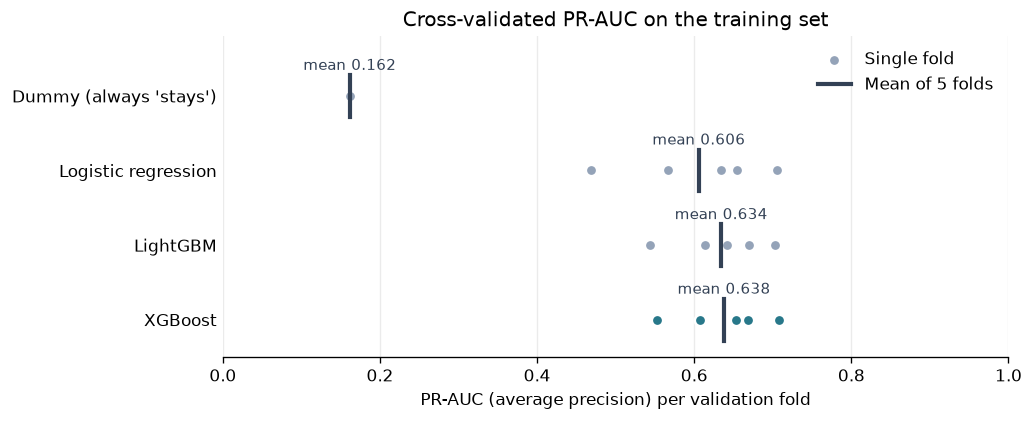

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 3.4), dpi=120, layout="constrained")
for row, model in enumerate(model_order):
    scores = paired[model]
    ax.scatter(scores, np.full(len(scores), row), s=46, color=FINAL_COLOR if model == final_name else MUTED,
               edgecolor="white", linewidth=1.5, zorder=3, label="Single fold" if row == 0 else None)
    ax.plot([scores.mean()] * 2, [row - 0.28, row + 0.28], color=INK, linewidth=2.5, zorder=4,
            label="Mean of 5 folds" if row == 0 else None)
    ax.annotate(f"mean {scores.mean():.3f}", (scores.mean(), row - 0.3), ha="center", va="bottom",
                fontsize=9, color=INK)
ax.set_yticks(range(len(model_order)), model_order)
ax.set_ylim(len(model_order) - 0.5, -0.8)
ax.set(xlim=(0, 1), xlabel="PR-AUC (average precision) per validation fold",
       title="Cross-validated PR-AUC on the training set")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(loc="upper right", frameon=False)
plt.show()

**Selection: XGBoost, by a very small margin.** XGBoost has the higher mean PR-AUC (0.638 vs. 0.634 for LightGBM). Across the five folds the paired difference averages +0.004 with a standard deviation of 0.016, and XGBoost is ahead in only 3 of 5 folds. On this data the two libraries perform the same, and the difference lies well within the fold-to-fold spread. XGBoost is kept because of the rule fixed in advance, not because it is meaningfully better.

Both searches chose **stumps** (`max_depth = 1`). Every tree uses a single feature, so the model adds up non-linear effects of individual features but does not model interactions between them. LightGBM's `num_leaves = 7` has no effect at depth 1, because a stump always has two leaves. With 1,176 training employees, deeper trees did not generalise better. Both boosting models are ahead of the weighted logistic regression reference (0.606), and all three are far above the dummy (0.162).

### Sensitivity check: do the class weights improve the ranking?

The class weights are a project decision (Section 4). This check refits the selected setting and the logistic regression on the same folds **without** weights and leaves everything else unchanged.

In [12]:
weight_check = {
    (final_name, "scale_pos_weight ≈ 5.2 (used)"): final_search.best_estimator_,
    (final_name, "no weights"): clone(final_search.best_estimator_).set_params(model__scale_pos_weight=1),
    ("Logistic regression", "class_weight='balanced' (used)"): baselines["Logistic regression"],
    ("Logistic regression", "no weights"): clone(baselines["Logistic regression"]).set_params(model__class_weight=None),
}
weight_rows = {}
for key, model in weight_check.items():
    result = cross_validate(model, X_train, y_train, cv=cv_folds, n_jobs=-1,
                            scoring={m: scoring[m] for m in ["pr_auc", "roc_auc"]})
    weight_rows[key] = {
        metric_names[m]: f"{result[f'test_{m}'].mean():.3f} ± {result[f'test_{m}'].std(ddof=1):.3f}"
        for m in ["pr_auc", "roc_auc"]
    }
weight_table = pd.DataFrame(weight_rows).T
weight_table.index.names = ["5-fold CV on training set", "Class weights"]
display(weight_table)

PR-AUC  \
5-fold CV on training set Class weights                                   
XGBoost                   scale_pos_weight ≈ 5.2 (used)   0.638 ± 0.060   
                          no weights                      0.662 ± 0.057   
Logistic regression       class_weight='balanced' (used)  0.606 ± 0.091   
                          no weights                      0.651 ± 0.068   

                                                                ROC-AUC  
5-fold CV on training set Class weights                                  
XGBoost                   scale_pos_weight ≈ 5.2 (used)   0.834 ± 0.020  
                          no weights                      0.842 ± 0.028  
Logistic regression       class_weight='balanced' (used)  0.827 ± 0.032  
                          no weights                      0.839 ± 0.032

**Result: the weights do not improve the ranking.** Without weights, XGBoost reaches a PR-AUC of 0.662 instead of 0.638, and the logistic regression 0.651 instead of 0.606. The weights mainly push the scores upwards, so that the default threshold of 0.5 already flags many employees. Because the threshold is optimised separately anyway, this shift brings no benefit here. Two consequences:

- The class weights stay in place as the agreed project design. In this check, however, they cost some ranking quality. Leaving them out would be a reasonable alternative.
- Without weights on either side, the plain logistic regression (0.651) and XGBoost (0.662) are on par, within the fold spread. The tuned logistic regression in [logistic_regression.ipynb](logistic_regression.ipynb), with its own feature engineering, reached a cross-validated AP of about 0.69 (on different folds). On this dataset gradient boosting brings **no clear gain in predictive quality** over a well-built linear model. This fits the stumps chosen above: the signal is largely additive.

XGBoost nevertheless remains the final model. As explained in the introduction, the choice follows the purpose of the exercise (explaining a black box with LIME), not a gain in accuracy.

## 7. Choose the decision threshold on training data

A score becomes an alert once it reaches a threshold. The default of 0.5 is arbitrary, especially for weighted models. The threshold is therefore chosen on **out-of-fold predictions**: each training employee is scored by a model that was fitted on the other four folds (same folds, best setting). The threshold that maximises F1 for the class "Leaves" is kept, giving missed leavers and false alarms equal weight. The test set plays no part.

The logistic regression reference gets its threshold through the same procedure, so the test comparison treats both models alike.

In [13]:
reference_name = "Logistic regression"


def f1_optimal_threshold(labels, scores):
    precision, recall, thresholds = precision_recall_curve(labels, scores)
    precision, recall = precision[:-1], recall[:-1]  # the last curve point has no threshold
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return float(thresholds[f1.argmax()])


oof_scores = {
    final_name: cross_val_predict(final_search.best_estimator_, X_train, y_train, cv=cv_folds,
                                  method="predict_proba", n_jobs=-1)[:, 1],
    reference_name: cross_val_predict(baselines[reference_name], X_train, y_train, cv=cv_folds,
                                      method="predict_proba", n_jobs=-1)[:, 1],
}
thresholds = {name: f1_optimal_threshold(y_train, scores) for name, scores in oof_scores.items()}


def alert_metrics(labels, scores, threshold):
    alerts = scores >= threshold
    return {
        "Threshold": threshold,
        "Precision": precision_score(labels, alerts, zero_division=0),
        "Recall": recall_score(labels, alerts),
        "F1 (Leaves)": f1_score(labels, alerts, zero_division=0),
        "Alerts": int(alerts.sum()),
    }


oof_table = pd.DataFrame(
    {(name, rule): alert_metrics(y_train, scores, threshold)
     for name, scores in oof_scores.items()
     for rule, threshold in [("Default 0.5", 0.5), ("F1-optimal", thresholds[name])]}
).T
oof_table.index.names = ["Out-of-fold, training set", "Threshold rule"]
display(oof_table.astype({"Alerts": int}).round(3))
print(f"Chosen threshold for {final_name}: {thresholds[final_name]:.3f}")

Threshold  Precision  Recall  \
Out-of-fold, training set Threshold rule                                 
XGBoost                   Default 0.5         0.500      0.434   0.721   
                          F1-optimal          0.741      0.703   0.511   
Logistic regression       Default 0.5         0.500      0.368   0.737   
                          F1-optimal          0.724      0.599   0.574   

                                          F1 (Leaves)  Alerts  
Out-of-fold, training set Threshold rule                       
XGBoost                   Default 0.5           0.542     316  
                          F1-optimal            0.591     138  
Logistic regression       Default 0.5           0.491     380  
                          F1-optimal            0.586     182

Chosen threshold for XGBoost: 0.741


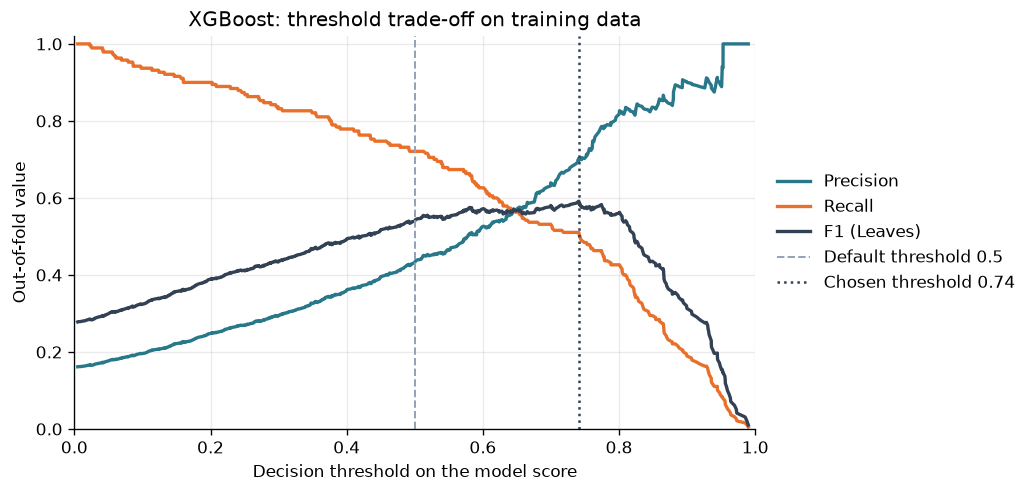

In [14]:
precision, recall, cutoffs = precision_recall_curve(y_train, oof_scores[final_name])
f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)

fig, ax = plt.subplots(figsize=(8.5, 4), dpi=120, layout="constrained")
curves = [("Precision", precision[:-1], FINAL_COLOR, "-"), ("Recall", recall[:-1], REFERENCE_COLOR, "-"),
          ("F1 (Leaves)", f1[:-1], INK, "-")]
for label, values, color, style in curves:
    ax.plot(cutoffs, values, color=color, linewidth=2, linestyle=style, label=label)
ax.axvline(0.5, color=MUTED, linestyle="--", linewidth=1.2, label="Default threshold 0.5")
ax.axvline(thresholds[final_name], color=INK, linestyle=":", linewidth=1.5,
           label=f"Chosen threshold {thresholds[final_name]:.2f}")
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="Decision threshold on the model score",
       ylabel="Out-of-fold value", title=f"{final_name}: threshold trade-off on training data")
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.show()

On the out-of-fold predictions, F1 peaks at a threshold of **0.74** (precision 70%, recall 51%, F1 0.59). Because the weights push all scores upwards, the optimum lies well above 0.5.

The F1 curve is almost flat between about 0.5 and 0.8 (F1 0.54–0.59). In that range the threshold barely changes F1, but it shifts the balance between catching leavers (recall) and avoiding false alarms (precision). The chosen value sits near the upper end of this plateau, where recall falls quickly. On new data, a small shift in the scores can therefore cost noticeable recall. In practice the threshold is a business decision about which error is more expensive, and F1 is only one neutral choice.

## 8. Final evaluation on the test set

The final pipeline was refitted on all 1,176 training employees with the best setting. It now scores the 294 test employees once, using the thresholds fixed in Section 7. The two reference models are refitted on the same training rows.

In [15]:
final_pipeline = final_search.best_estimator_
reference_pipeline = clone(baselines[reference_name]).fit(X_train, y_train)
dummy = clone(baselines["Dummy (always 'stays')"]).fit(X_train, y_train)

test_scores = {
    final_name: final_pipeline.predict_proba(X_test)[:, 1],
    reference_name: reference_pipeline.predict_proba(X_test)[:, 1],
    "Dummy (always 'stays')": dummy.predict_proba(X_test)[:, 1],
}
decision_rules = [
    (final_name, "Default 0.5", 0.5),
    (final_name, "F1-optimal (from CV)", thresholds[final_name]),
    (reference_name, "Default 0.5", 0.5),
    (reference_name, "F1-optimal (from CV)", thresholds[reference_name]),
    ("Dummy (always 'stays')", "—", 0.5),
]

test_rows = []
for model, rule, threshold in decision_rules:
    scores = test_scores[model]
    alerts = scores >= threshold
    tn, fp, fn, tp = confusion_matrix(y_test, alerts, labels=[0, 1]).ravel()
    test_rows.append({
        "Model": model, "Threshold rule": rule, "Threshold": threshold,
        "PR-AUC": average_precision_score(y_test, scores), "ROC-AUC": roc_auc_score(y_test, scores),
        "Precision": precision_score(y_test, alerts, zero_division=0), "Recall": recall_score(y_test, alerts),
        "F1 (Leaves)": f1_score(y_test, alerts, zero_division=0), "Accuracy": accuracy_score(y_test, alerts),
        "Leavers detected": f"{tp} of {tp + fn}", "False alarms": fp,
    })
test_results = pd.DataFrame(test_rows).set_index(["Model", "Threshold rule"])
display(test_results.round(3))

Threshold  PR-AUC  ROC-AUC  \
Model                  Threshold rule                                     
XGBoost                Default 0.5               0.500   0.597    0.823   
                       F1-optimal (from CV)      0.741   0.597    0.823   
Logistic regression    Default 0.5               0.500   0.561    0.803   
                       F1-optimal (from CV)      0.724   0.561    0.803   
Dummy (always 'stays') —                         0.500   0.160    0.500   

                                             Precision  Recall  F1 (Leaves)  \
Model                  Threshold rule                                         
XGBoost                Default 0.5               0.444   0.766        0.562   
                       F1-optimal (from CV)      0.692   0.383        0.493   
Logistic regression    Default 0.5               0.349   0.638        0.451   
                       F1-optimal (from CV)      0.538   0.447        0.488   
Dummy (always 'stays') —                         0.000   0.000        0.000   

                                             Accuracy Leavers detected  \
Model                  Threshold rule                                    
XGBoost                Default 0.5              0.810         36 of 47   
                       F1-optimal (from CV)     0.874         18 of 47   
Logistic regression    Default 0.5              0.752         30 of 47   
                       F1-optimal (from CV)     0.850         21 of 47   
Dummy (always 'stays') —                        0.840          0 of 47   

                                             False alarms  
Model                  Threshold rule                      
XGBoost                Default 0.5                     45  
                       F1-optimal (from CV)             8  
Logistic regression    Default 0.5                     56  
                       F1-optimal (from CV)            18  
Dummy (always 'stays') —                                0

### Confusion matrices of the final model

Rows show what actually happened, columns show what the model predicted. The bottom-right cell counts leavers the model caught. The top-right cell counts false alarms.

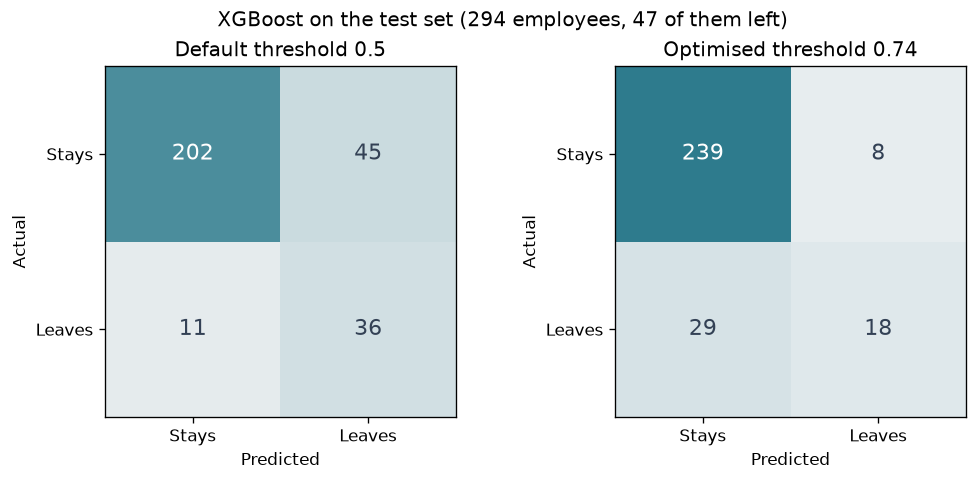

In [16]:
cmap = sns.light_palette(FINAL_COLOR, as_cmap=True)
color_max = int((y_test == 0).sum())  # same colour scale for both matrices
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.9), dpi=120, layout="constrained")
for ax, (title, threshold) in zip(
    axes, [("Default threshold 0.5", 0.5), (f"Optimised threshold {thresholds[final_name]:.2f}", thresholds[final_name])]
):
    display_cm = ConfusionMatrixDisplay.from_predictions(
        y_test, test_scores[final_name] >= threshold, labels=[0, 1], display_labels=CLASS_LABELS,
        cmap=cmap, colorbar=False, ax=ax, im_kw={"vmin": 0, "vmax": color_max},
    )
    for text, count in zip(display_cm.text_.ravel(), display_cm.confusion_matrix.ravel()):
        text.set(color="white" if count > color_max / 2 else INK, fontsize=13)
    ax.set(title=title, xlabel="Predicted", ylabel="Actual")
fig.suptitle(f"{final_name} on the test set ({len(y_test)} employees, {y_test.sum()} of them left)")
plt.show()

### Classification reports

The rows "Stays" and "Leaves" show precision, recall and F1 for each class. The final model is shown at both thresholds, the logistic regression reference at its own F1-optimal threshold.

In [17]:
for model, rule, threshold in [decision_rules[0], decision_rules[1], decision_rules[3]]:
    print(f"{model} · {rule} (threshold {threshold:.3f})")
    print(classification_report(y_test, test_scores[model] >= threshold, labels=[0, 1],
                                target_names=CLASS_LABELS, digits=3, zero_division=0))

XGBoost · Default 0.5 (threshold 0.500)
              precision    recall  f1-score   support

       Stays      0.948     0.818     0.878       247
      Leaves      0.444     0.766     0.562        47

    accuracy                          0.810       294
   macro avg      0.696     0.792     0.720       294
weighted avg      0.868     0.810     0.828       294

XGBoost · F1-optimal (from CV) (threshold 0.741)
              precision    recall  f1-score   support

       Stays      0.892     0.968     0.928       247
      Leaves      0.692     0.383     0.493        47

    accuracy                          0.874       294
   macro avg      0.792     0.675     0.711       294
weighted avg      0.860     0.874     0.859       294

Logistic regression · F1-optimal (from CV) (threshold 0.724)
              precision    recall  f1-score   support

       Stays      0.898     0.927     0.912       247
      Leaves      0.538     0.447     0.488        47

    accuracy                    

### ROC and precision-recall curves

The curves show the ranking quality over all thresholds and do not depend on the chosen cut-off. The dashed line is chance level, which is also what the dummy classifier achieves. The dot marks the final model at its optimised threshold.

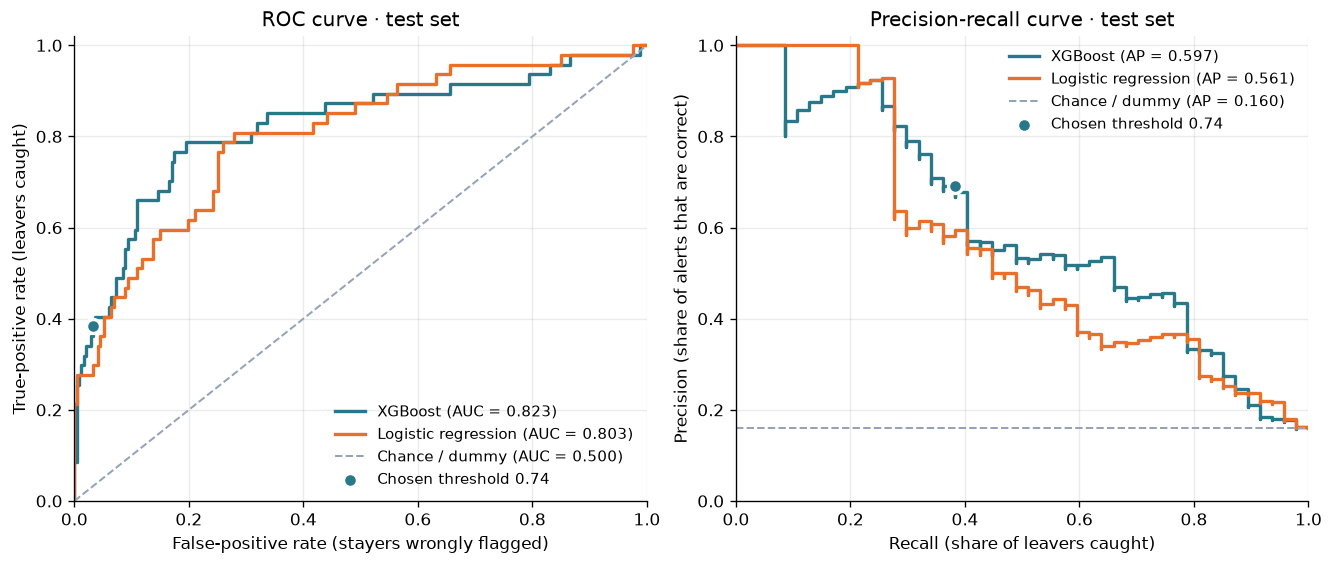

In [18]:
fig, (roc_ax, pr_ax) = plt.subplots(1, 2, figsize=(11, 4.6), dpi=120, layout="constrained")
for model, color in [(final_name, FINAL_COLOR), (reference_name, REFERENCE_COLOR)]:
    scores = test_scores[model]
    fpr, tpr, _ = roc_curve(y_test, scores)
    roc_ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{model} (AUC = {roc_auc_score(y_test, scores):.3f})")
    precision, recall, _ = precision_recall_curve(y_test, scores)
    pr_ax.step(recall, precision, where="post", color=color, linewidth=2,
               label=f"{model} (AP = {average_precision_score(y_test, scores):.3f})")

roc_ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1.2, label="Chance / dummy (AUC = 0.500)")
pr_ax.axhline(y_test.mean(), color=MUTED, linestyle="--", linewidth=1.2,
              label=f"Chance / dummy (AP = {y_test.mean():.3f})")

# Operating point of the final model at the chosen threshold.
chosen_alerts = test_scores[final_name] >= thresholds[final_name]
point_recall = recall_score(y_test, chosen_alerts)
point_fpr = chosen_alerts[y_test.to_numpy() == 0].mean()
point_precision = precision_score(y_test, chosen_alerts)
roc_ax.scatter(point_fpr, point_recall, s=70, color=FINAL_COLOR, edgecolor="white", linewidth=2, zorder=5,
               label=f"Chosen threshold {thresholds[final_name]:.2f}")
pr_ax.scatter(point_recall, point_precision, s=70, color=FINAL_COLOR, edgecolor="white", linewidth=2, zorder=5,
              label=f"Chosen threshold {thresholds[final_name]:.2f}")

roc_ax.set(xlabel="False-positive rate (stayers wrongly flagged)", ylabel="True-positive rate (leavers caught)",
           title="ROC curve · test set")
pr_ax.set(xlabel="Recall (share of leavers caught)", ylabel="Precision (share of alerts that are correct)",
          title="Precision-recall curve · test set")
for ax in (roc_ax, pr_ax):
    ax.set(xlim=(0, 1), ylim=(0, 1.02))
    ax.grid(alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
roc_ax.legend(loc="lower right", frameon=False, fontsize=9)
pr_ax.legend(loc="upper right", frameon=False, fontsize=9)
plt.show()

### How certain are the test numbers?

The test set contains only 47 leavers, so each missed or caught leaver moves recall by about 2 percentage points. A bootstrap (1,000 resamples of the 294 test employees) shows how much the test metrics of the final model could vary with a different sample of the same size.

In [19]:
rng = np.random.default_rng(RANDOM_STATE)
labels, scores = y_test.to_numpy(), test_scores[final_name]
alerts = scores >= thresholds[final_name]
bootstrap = []
for _ in range(1000):
    sample = rng.integers(0, len(labels), len(labels))
    bootstrap.append({
        "PR-AUC": average_precision_score(labels[sample], scores[sample]),
        "ROC-AUC": roc_auc_score(labels[sample], scores[sample]),
        "Precision": precision_score(labels[sample], alerts[sample], zero_division=0),
        "Recall": recall_score(labels[sample], alerts[sample]),
    })
bootstrap = pd.DataFrame(bootstrap)
point_estimates = test_results.loc[(final_name, "F1-optimal (from CV)"), list(bootstrap.columns)]
display(pd.DataFrame({
    "Test value": point_estimates.astype(float),
    "95% interval, lower": bootstrap.quantile(0.025),
    "95% interval, upper": bootstrap.quantile(0.975),
}).round(3))

,Test value,"95% interval, lower","95% interval, upper"
PR-AUC,0.597,0.455,0.740
ROC-AUC,0.823,0.740,0.898
Precision,0.692,0.519,0.870
Recall,0.383,0.244,0.537


### What does this mean in practice?

In [20]:
tn, fp, fn, tp = confusion_matrix(y_test, alerts, labels=[0, 1]).ravel()
print(f"Test set: {len(y_test)} employees, {tp + fn} of whom actually left.")
print(f"At threshold {thresholds[final_name]:.2f}, {final_name} flags {tp + fp} employees as likely to leave.")
print(f"  Caught:       {tp} of {tp + fn} leavers ({tp / (tp + fn):.0%})")
print(f"  Missed:       {fn} leavers")
print(f"  False alarms: {fp} of {tn + fp} stayers ({fp / (tn + fp):.0%}); {tp / (tp + fp):.0%} of all alerts are correct")

Test set: 294 employees, 47 of whom actually left.
At threshold 0.74, XGBoost flags 26 employees as likely to leave.
  Caught:       18 of 47 leavers (38%)
  Missed:       29 leavers
  False alarms: 8 of 247 stayers (3%); 69% of all alerts are correct


- **Ranking quality:** test PR-AUC 0.597 and ROC-AUC 0.823, close to the cross-validation values (0.638 and 0.834) and far above chance (0.160 and 0.5). The 95% bootstrap interval for PR-AUC is wide (0.46–0.74), because the test set contains only 47 leavers.
- **Optimised threshold (0.74):** the model flags 26 of 294 employees, and 18 of them actually left. That is a precision of 69%, more than four times the base rate of 16%. However, it catches only 18 of 47 leavers (38% recall) and misses 29. False alarms are rare: 8 of 247 stayers (3%).
- **Default threshold (0.5):** the model flags 81 employees and catches 36 of 47 leavers (77%), but also raises 45 false alarms (44% precision). On the test set this gives the higher F1 (0.56 vs. 0.49). The F1-optimal threshold from cross-validation did not transfer exactly, as the flat F1 curve in Section 7 suggested: recall dropped from 51% (out-of-fold) to 38%.
- **Accuracy is misleading:** 87% at the optimised threshold sounds good, but the dummy that never flags anyone already reaches 84%.
- **Against the reference:** XGBoost ranks slightly better than the weighted logistic regression (PR-AUC 0.597 vs. 0.561), and at their CV thresholds both reach an F1 of 0.49. The gap is much smaller than the bootstrap uncertainty. On the same test employees, the tuned logistic regression in [logistic_regression.ipynb](logistic_regression.ipynb) reported AP 0.66–0.67.

## 9. Export for the LIME notebook

All objects are stored with `joblib` in `artifacts/`:

| File | Content |
|---|---|
| `final_pipeline.joblib` | Fitted pipeline (ordinal encoder + final model). `predict_proba` accepts the cleaned raw DataFrame. |
| `data_splits.joblib` | `X_train`, `X_test`, `y_train`, `y_test` (raw cleaned features, target 1 = leaves) |
| `model_metadata.joblib` | Model name and settings, chosen threshold, feature names, indices of the categorical columns, category mapping, class names and library versions |

**How the pieces fit together for LIME.** `pipeline.named_steps["preprocess"].transform(X)` returns the numeric matrix that LIME perturbs. Its columns follow `feature_names`, and the categorical columns sit at `categorical_feature_indices` (0–6) as integer codes. `categorical_names[i][code]` returns the text label of a code, e.g. `categorical_names[6][1] == "Yes"` for `OverTime`. On that matrix, `pipeline.named_steps["model"].predict_proba` gives the same scores as the full pipeline on the raw rows.

Pickled models are tied to the library versions, so the metadata records them. The pipeline contains only scikit-learn, LightGBM and XGBoost classes, so loading it needs no code from this notebook.

In [21]:
ARTIFACT_DIR.mkdir(exist_ok=True)

fitted_encoder = final_pipeline.named_steps["preprocess"].named_transformers_["categorical"]
assert list(final_pipeline.named_steps["preprocess"].get_feature_names_out()) == feature_names
categorical_feature_indices = [feature_names.index(column) for column in categorical_columns]
categorical_names = {
    feature_names.index(column): [str(label) for label in categories]
    for column, categories in zip(categorical_columns, fitted_encoder.categories_)
}

metadata = {
    "model_name": final_name,
    "best_params": {param.removeprefix("model__"): value for param, value in final_search.best_params_.items()},
    "scale_pos_weight": float(scale_pos_weight),
    "threshold": thresholds[final_name],
    "threshold_rule": "F1-maximal on 5-fold out-of-fold predictions of the training set",
    "feature_names": feature_names,
    "categorical_columns": categorical_columns,
    "categorical_feature_indices": categorical_feature_indices,
    "categorical_names": categorical_names,
    "class_names": CLASS_LABELS,
    "target_definition": "1 = leaves (Attrition == 'Yes'), 0 = stays",
    "random_state": RANDOM_STATE,
    "versions": {"scikit-learn": sklearn.__version__, "lightgbm": lightgbm.__version__,
                 "xgboost": xgboost.__version__, "pandas": pd.__version__},
}

joblib.dump(final_pipeline, ARTIFACT_DIR / "final_pipeline.joblib")
joblib.dump({"X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test},
            ARTIFACT_DIR / "data_splits.joblib")
joblib.dump(metadata, ARTIFACT_DIR / "model_metadata.joblib")

for path in sorted(ARTIFACT_DIR.glob("*.joblib")):
    print(f"{path}  ({path.stat().st_size / 1024:,.0f} KB)")
print("Categorical feature indices:", categorical_feature_indices)

artifacts/data_splits.joblib  (465 KB)
artifacts/final_pipeline.joblib  (419 KB)
artifacts/model_metadata.joblib  (2 KB)
Categorical feature indices: [0, 1, 2, 3, 4, 5, 6]


### Reload the artifacts and score one employee

This cell needs only the files in `artifacts/` and can be copied into the LIME notebook as is. It scores a single test employee with the full pipeline, shows the encoded row LIME will work with and checks that both routes give the same score.

In [22]:
from pathlib import Path

import joblib
import numpy as np

artifact_dir = Path("artifacts")
pipeline = joblib.load(artifact_dir / "final_pipeline.joblib")
splits = joblib.load(artifact_dir / "data_splits.joblib")
meta = joblib.load(artifact_dir / "model_metadata.joblib")

employee = splits["X_test"].iloc[[0]]  # double brackets keep a one-row DataFrame
score = pipeline.predict_proba(employee)[0, 1]
predicted = meta["class_names"][int(score >= meta["threshold"])]
actual = meta["class_names"][int(splits["y_test"].iloc[0])]
print(f"{meta['model_name']} · employee row {employee.index[0]}")
print(f"Score {score:.3f} vs. threshold {meta['threshold']:.3f} -> predicted '{predicted}', actual '{actual}'")

# The same employee as the encoded row that LIME perturbs (integer codes at the categorical indices).
encoded = pipeline.named_steps["preprocess"].transform(employee)
decoded = {
    meta["feature_names"][i]: meta["categorical_names"][i][int(encoded[0, i])]
    for i in meta["categorical_feature_indices"]
}
print("Decoded categories:", decoded)
assert decoded == employee[meta["categorical_columns"]].iloc[0].to_dict()
assert np.isclose(pipeline.named_steps["model"].predict_proba(encoded)[0, 1], score)

XGBoost · employee row 1061
Score 0.639 vs. threshold 0.741 -> predicted 'Stays', actual 'Stays'
Decoded categories: {'BusinessTravel': 'Non-Travel', 'Department': 'Sales', 'EducationField': 'Life Sciences', 'Gender': 'Female', 'JobRole': 'Sales Representative', 'MaritalStatus': 'Married', 'OverTime': 'No'}


## 10. Conclusion

### Which ML algorithm did you choose and why?

**XGBoost**, a gradient-boosted decision-tree model. Gradient boosting fits this task because it handles a mix of measurements, ordered codes and integer-coded categories without scaling. It can capture non-linear effects, supports class weights for the rare class and provides the `predict_proba` that LIME needs.

**Why a tree ensemble and not logistic regression?** A logistic regression without weights or with feature engineering performs about as well on this data, so boosting adds no clear predictive gain. We still decided against it. A logistic regression can be interpreted directly through its coefficients, and LIME, which approximates a model locally with a linear model, would add little to it. The exercise asks us to make a model explainable with LIME. A sum of 541 trees cannot be read directly, so here LIME has real work to do.

**Why XGBoost and not LightGBM?** By the pre-defined rule, the higher mean cross-validated PR-AUC. The two were practically tied (0.638 vs. 0.634, a difference well within the fold-to-fold spread), so this choice is not decisive. Both are far better than the dummy and moderately better than the weighted logistic regression reference.

### What parameter settings did you use and why?

| Setting | Value | Reason |
|---|---|---|
| `max_depth` | 1 (stumps) | Chosen by the search. Deeper trees did not improve the cross-validated PR-AUC on 1,176 employees. |
| `n_estimators` / `learning_rate` | 541 / 0.082 | Many small correction steps instead of a few large ones |
| `min_child_weight` | 1.2 | Minimum (weighted) amount of data per leaf, close to the default of 1 |
| `subsample` / `colsample_bytree` | 0.70 / 0.76 | Each tree sees a random subset of employees and features, which reduces overfitting |
| `reg_lambda` | 7.7 | Strong L2 penalty on the leaf values, which makes predictions more stable |
| `scale_pos_weight` | 5.19 (= 986 / 190) | Class weight for the 16% leavers instead of SMOTE (Section 4) |
| Decision threshold | 0.74 | F1-maximal on out-of-fold training predictions (Section 7) |
| `random_state` | 42 | Reproducibility |

The values come from a randomized search over 50 settings per model, scored by PR-AUC on the same five stratified folds of the training set. The search ranges were deliberately small and conservative for a small dataset.

### Which train-test split did you use? Did you encounter problems?

A **stratified 80/20 split** with `random_state=42`: 1,176 training employees (190 leavers) and 294 test employees (47 leavers), the same partition as the EDA and the earlier notebooks. All tuning, model selection and the threshold choice used stratified 5-fold cross-validation on the training set only. The test set was scored once, at the end.

Problems we encountered:

1. **Class imbalance.** With only 16% leavers, accuracy is meaningless: never predicting an exit scores 84%. We therefore used PR-AUC as the main metric and class weights against the imbalance. The class weights turned out to lower the ranking quality slightly (Section 6).
2. **Small sample, large uncertainty.** PR-AUC varies by about ±0.06 between folds, more than the gaps between the models. With 47 leavers in the test set, one employee moves recall by about 2 percentage points, and the 95% interval for test recall spans 24–54%.
3. **Unstable threshold.** The F1-optimal threshold from cross-validation (0.74, recall 51%) caught only 38% of leavers on the test set, because F1 is almost flat over a wide range of thresholds.
4. **Test set re-used across the project.** The same test employees were reported in the earlier model notebooks, and the EDA covers the full data. No decision in this notebook used the test set, but across the project it is no longer completely fresh.
5. **Data limitations.** The data are fictional and form a snapshot without dates. We cannot verify that every feature was known *before* an employee resigned. `PerformanceRating` is fully determined by `PercentSalaryHike`, which LIME has to take into account.

### What is the performance of your model? Is it suitable for predicting/classifying employee attrition?

| Metric | Cross-validation (training set) | Test set |
|---|---|---|
| PR-AUC (chance = 0.16) | 0.638 ± 0.060 | 0.597 (95% CI 0.46–0.74) |
| ROC-AUC (chance = 0.5) | 0.834 ± 0.020 | 0.823 |
| Precision / recall at threshold 0.74 | 70% / 51% (out-of-fold) | 69% / 38% (18 of 47 leavers, 8 false alarms) |
| Precision / recall at threshold 0.5 | 43% / 72% (out-of-fold) | 44% / 77% (36 of 47 leavers, 45 false alarms) |

The model is **suitable for ranking employees by attrition risk**, i.e. for identifying a group in which exits are clearly more frequent than average. It is **not suitable for reliable individual predictions**. At any threshold it either misses many leavers or produces many false alarms. Within their uncertainty, the test results match the cross-validation results, so there is no sign of overfitting.

### Summary for management: can we reliably predict resignations?

**Not reliably for individual employees, but well enough to find groups at elevated risk.**

- **Better than chance, but far from perfect.** In the test group of 294 employees, 47 resigned (16%). Of the 26 employees the model flagged with its strict setting, 18 actually resigned: 7 out of 10 alerts were correct, compared with fewer than 2 out of 10 with a random selection.
- **It does not find everyone.** The strict setting catches only about 4 in 10 leavers. A more sensitive setting catches about 3 in 4, but then more than half of the alerts concern employees who would have stayed.
- **The setting is a management decision.** It depends on what costs more: an unexpected resignation, or a retention conversation with someone who was not going to leave.
- **Recommended use:** an early-warning list that prompts conversations and targeted measures, such as reducing overtime or offering development prospects. Decisions about individual employees should not be automated on the basis of this score. That also matters for data protection (GDPR) and works-council co-determination.
- **Before real use:** the model is based on fictional snapshot data. It would have to be validated on Passau MedCo's own data from a later period.

**Next step:** the LIME notebook explains individual predictions, i.e. which factors drive a particular employee's risk score. This explanation makes the score usable for HR conversations.